### 1. Link Census data (population, mobile home share)
 * To analyze relationships between population density, mobile home share and casualties, We linked the census data to our tornado data.
   * Census data : Census API
   * County area data : Gazetteer Files (https://www.census.gov/geographies/reference-files/time-series/geo/gazetteer-files.html)

In [ ]:
import pandas as pd
import numpy as np

tor_clean = pd.read_csv("https://raw.githubusercontent.com/hbingley/DangerousTornadoes/refs/heads/main/data/tornado_clean.csv")
tor_county = pd.read_csv("https://raw.githubusercontent.com/hbingley/DangerousTornadoes/refs/heads/main/data/tornado_county.csv", dtype={"fips": str})


In [ ]:
import requests
from google.colab import userdata
KEY = userdata.get("CENSUS_KEY")

def get_census(url, vars_):
  r = requests.get(url, params = {"get": vars_, "for": "county:*", "key": KEY},
                   timeout=60)
  r.raise_for_status()
  js = r.json()
  return pd.DataFrame(js[1:], columns = js[0])

frames = []

# ACS Population, Housing data: 2005-2009 ~ 2020-2024
for y in range(2009, 2025):
  d = get_census(f"https://api.census.gov/data/{y}/acs/acs5",
                 "B01003_001E,B25024_001E,B25024_010E")
  d["census_yr"] = y
  frames.append(d)
  print(y, len(d))

2009 3221
2010 3221
2011 3221
2012 3221
2013 3221
2014 3220
2015 3220
2016 3220
2017 3220
2018 3220
2019 3220
2020 3221
2021 3221
2022 3222
2023 3222
2024 3222


In [ ]:
# 2000 Census: Population, Housing
p = get_census("https://api.census.gov/data/2000/dec/sf1", "P001001")
h = get_census("https://api.census.gov/data/2000/dec/sf3", "H030001,H030010")
c2000 = p.merge(h, on=["state", "county"]).rename(columns=
 {"P001001": "B01003_001E", "H030001": "B25024_001E", "H030010": "B25024_010E"})
c2000["census_yr"] = 2000

In [ ]:
# census file generate
census = pd.concat([c2000] + frames, ignore_index=True)
census["fips"] = census["state"] + census ["county"]
census = census.rename(columns = {"B01003_001E": "pop", "B25024_001E": "housing",
                                  "B25024_010E": "mobile"})
census = census[["census_yr", "fips", "pop", "housing", "mobile"]]
census[["pop", "housing", "mobile"]] = census[["pop", "housing", "mobile"]].apply(pd.to_numeric)
census = census[census["fips"].str[:2] != "72"]
census.to_csv("county_census.csv", index=False)

In [ ]:
# area
gz = pd.read_csv("https://raw.githubusercontent.com/hbingley/DangerousTornadoes/refs/heads/main/data/2012_Gaz_counties_national.txt", sep="\t", dtype={"GEOID": str})
gz.columns = gz.columns.str.strip() # remove whitespaces

gz = gz.rename(columns = {"GEOID": "fips", "ALAND_SQMI": "land_sqmi"})[["fips", "land_sqmi"]]

* There are some changes to counties, so we changed county codes by this information:
  * Substantial Changes to Counties and County Equivalent Entities: 1970-Present (https://www.census.gov/programs-surveys/geography/technical-documentation/county-changes.html)

* Changes:
  * Dade County, Florida (12-025):
Renamed as Miami-Dade County (12-086) effective July 22, 1997.
  * Oglala Lakota County, South Dakota (46-102)
Changed name and code from Shannon County (46-113) effective May 1, 2015.
  * Bedford (independent) city, Virginia (51-515):
Changed to town status and added to Bedford County (51-019) effective July 1, 2013.

In [ ]:
# reflect county changes
fix = {"12025": "12086",  # Miami
       "46113": "46102",  # Oglala
       "51515": "51019"}  # Bedford

census["fips"] = census["fips"].replace(fix)
census = census.groupby(["census_yr", "fips"], as_index=False)[["pop", "housing", "mobile"]].sum()
gz["fips"] = gz["fips"].replace(fix)
gz = gz.groupby("fips", as_index=False)["land_sqmi"].sum()

In [ ]:
tor_county = pd.read_csv("https://raw.githubusercontent.com/hbingley/DangerousTornadoes/refs/heads/main/data/tornado_county.csv", dtype={"fips": str})
tor_clean = pd.read_csv("https://raw.githubusercontent.com/hbingley/DangerousTornadoes/refs/heads/main/data/tornado_clean.csv")

# year information
tc = tor_county.merge(tor_clean[["tor_id", "yr"]], on="tor_id", how="left", validate="many_to_one")

# tc.head()

# 1995-2008 -> 2000 Census, 2009-2024 -> ACS of each year, 2025 -> 2024 ACS
tc["census_yr"] = tc["yr"]
tc.loc[tc["yr"] <= 2008, "census_yr"] = 2000
tc.loc[tc["yr"] >= 2025, "census_yr"] = 2024


* New Counties or County Equivalent Entities
  * State of Connecticut (09): Finalized adoption of the State’s nine Councils of Governments (COGs) as the county-equivalent geographic unit.
  * County codes changed from (09001, 09003, 09005, 09007, 09009, 09011, 09013, 09015) to (09110, 09120, 09130, 09140, 09150, 09160, 09170, 09180, 09190), and the previous code applied to the tornado data.

In [ ]:
# CT
ct = tc["fips"].str.startswith("09") & (tc["census_yr"] >= 2022)
tc.loc[ct, "census_yr"] = 2021

In [ ]:
# reflect county changes
tc["fips"] = tc["fips"].replace(fix)
# tc = tc.drop_duplicates(["tor_id", "fips"])

In [ ]:
# census + area
tcx = tc.merge(census, on=["census_yr", "fips"], how="left",
               validate = "many_to_one", indicator=True)
print(tcx["_merge"].value_counts())
tcx = tcx.merge(gz, on="fips", how="left", validate="many_to_one")
print(tcx["land_sqmi"].isna().sum())

_merge
both          43978
left_only         2
right_only        0
Name: count, dtype: int64
2


In [ ]:
tcx[tcx["_merge"] == "left_only"][["tor_id", "yr", "fips"]]

,tor_id,yr,fips
1947,36728,1996,42159
39728,35195,1995,21022


* 2 tornado-county pairs were unmatched to Census data. These pairs have county codes that do not exist and they appear to be entry errors.
* Both tornadoes have other valid counties, so we drop only these 2 pairs.

In [ ]:
tcx = tcx[tcx["_merge"] == "both"].drop(columns="_merge")

In [ ]:
# aggregate each tornado
agg = tcx.groupby("tor_id").agg(pop=("pop", "sum"), housing = ("housing", "sum"),
                                mobile=("mobile", "sum"), land_sqmi=("land_sqmi", "sum"))

# calculate population density and mobile home ratio (percent)
agg["pop_density"] = agg["pop"] / agg["land_sqmi"]
agg["mobile_pct"] = 100 * agg["mobile"] / agg["housing"]

# merge to tornado_clean
tor_clean = tor_clean.merge(agg.reset_index(),
                            on = "tor_id", how="left", validate="one_to_one")

# check
print(tor_clean[["pop_density", "mobile_pct"]].describe())
print(tor_clean["pop_density"].isna().sum())

        pop_density    mobile_pct
count  39219.000000  39219.000000
mean     177.312354     12.847506
std      590.536319      8.937765
min        0.100161      0.002360
25%       17.513403      5.680382
50%       45.862981     10.929890
75%      128.972379     18.336314
max    34836.141277     59.225996
0


In [ ]:
# Save csv

tor_clean["mag"].isna().sum()
tor_clean = tor_clean.drop(["date", "time"], axis=1)
tor_clean.columns
tor_clean.to_csv("tornado_census.csv", index=False)

### 2. EDA for Census data

In [ ]:
import matplotlib.pyplot as plt

df = pd.read_csv("https://raw.githubusercontent.com/hbingley/DangerousTornadoes/refs/heads/main/data/tornado_census.csv")
df["casualty"] = ((df["inj"] + df["fat"]) > 0).astype(int)

#### (1) Casualty analysis

In [ ]:
# Casualties analysis
target = pd.DataFrame({
    "tornadoes": df["casualty"].value_counts().sort_index(),
    "share (%)": (100* df["casualty"].value_counts(normalize=True).sort_index()).round(1)
})
target.index = ["No casualty", "Casualty"]
display(target)

,tornadoes,share (%)
No casualty,36330,92.6
Casualty,2889,7.4


* Our target feature (Casualties = Injuries + Fatalities) only accounts for 7.4% of the data.
* It implies that we cannot use an Accuracy for ML validation.

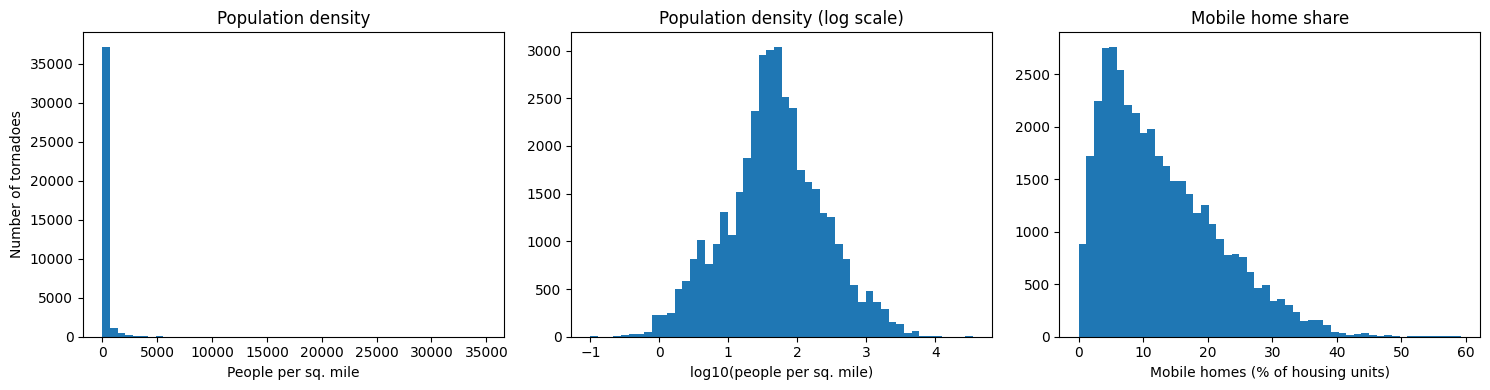

In [ ]:
# Census features EDA
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].hist(df["pop_density"], bins=50)
ax[0].set(title="Population density", xlabel="People per sq. mile", ylabel="Number of tornadoes")

ax[1].hist(np.log10(df["pop_density"]), bins=50)
ax[1].set(title="Population density (log scale)", xlabel="log10(people per sq. mile)")

ax[2].hist(df["mobile_pct"], bins=50)
ax[2].set(title="Mobile home share", xlabel="Mobile homes (% of housing units)")

plt.tight_layout()
plt.show()

* Population density is highly right-skewed (figure 1), so we applied log transformation to this data. The figure 2 illustrates approximate normal distribution.
* Mobile home data is also right-skewed, but the skewness is not extremely high to apply the log transformation.

#### (2) Casualty rate by population density and mobile home share

,mean,size,pct,label
density_q,,,,
Q1 (lowest),0.026007,9805,2.600714,2.6%\nn=9805
Q2,0.071691,9806,7.169080,7.2%\nn=9806
Q3,0.100571,9804,10.057120,10.1%\nn=9804
Q4 (highest),0.096389,9804,9.638923,9.6%\nn=9804


,mean,size,pct,label
mobile_q,,,,
Q1 (lowest),0.057618,9806,5.761779,5.8%\nn=9806
Q2,0.060996,9804,6.099551,6.1%\nn=9804
Q3,0.079253,9804,7.925337,7.9%\nn=9804
Q4 (highest),0.096787,9805,9.678735,9.7%\nn=9805


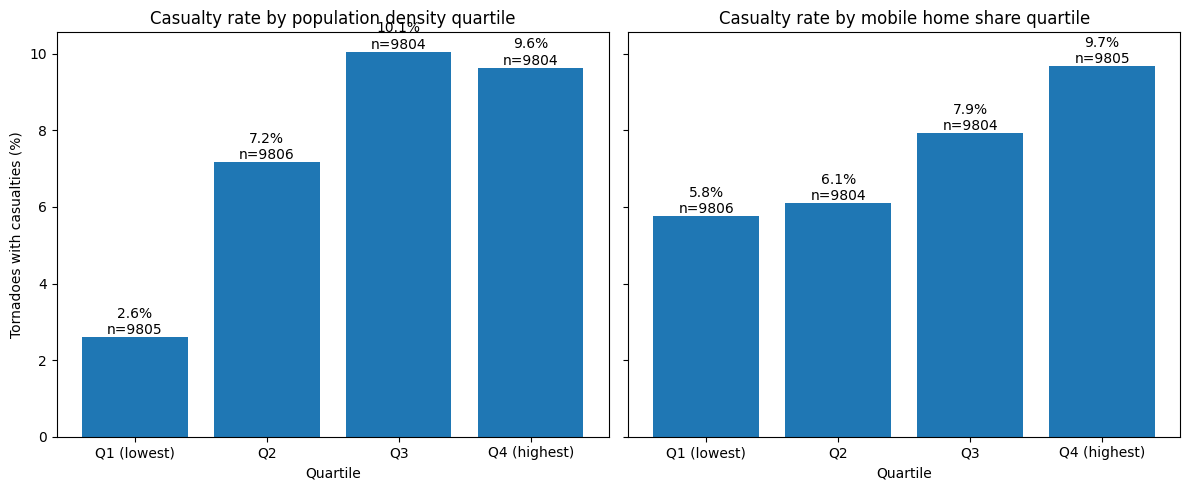

In [ ]:
# Casualty rate by population density and mobile home share

# Split into quartiles (about 9,800 tornadoes each)
q_labels = ["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"]
df["density_q"] = pd.qcut(df["pop_density"], 4, labels=q_labels)
df["mobile_q"] = pd.qcut(df["mobile_pct"], 4, labels=q_labels)

# Casualty rate
dens_rate = df.groupby("density_q", observed=True)["casualty"].agg(["mean", "size"])
mob_rate = df.groupby("mobile_q", observed=True)["casualty"].agg(["mean", "size"])

dens_rate["pct"] = 100 * dens_rate["mean"]
mob_rate["pct"] = 100 * mob_rate["mean"]

# Labels
dens_rate["label"] = dens_rate["pct"].round(1).astype(str) + "%\nn=" + dens_rate["size"].astype(str)
mob_rate["label"] = mob_rate["pct"].round(1).astype(str) + "%\nn=" + mob_rate["size"].astype(str)

display(dens_rate)
display(mob_rate)

# Plot
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

bars = ax[0].bar(q_labels, dens_rate["pct"])
ax[0].bar_label(bars, labels=dens_rate["label"])
ax[0].set(title="Casualty rate by population density quartile", xlabel="Quartile",
          ylabel="Tornadoes with casualties (%)")

bars = ax[1].bar(q_labels, mob_rate["pct"])
ax[1].bar_label(bars, labels=mob_rate["label"])
ax[1].set(title="Casualty rate by mobile home share quartile", xlabel="Quartile")

plt.tight_layout()
plt.show()

* Population density
  * The casualty rate rises sharply from the lowest-density quartile to the middle quartiles (2.6% -> 7.2% -> 10.1%). However, it slightly decreases in the highest quartile (9.6%).
* Mobile home share
  * The casualty rate increases steadily with the share of mobile homes, from 5.8% to 9.7%.
* These are simple comparisons, so we should test these relationships with controls (tornado strength, size, region, etc.).

#### (3) Mobile home share and casualty rate by year

In [ ]:
# Mobile home share and casualty rate by year
yearly = df.groupby("yr").agg(mobile_pct=("mobile_pct", "mean"),
                              casualty_pct=("casualty", "mean"))
yearly["casualty_pct"] = 100 * yearly["casualty_pct"]
display(yearly.round(1))

corr = yearly["mobile_pct"].corr(yearly["casualty_pct"])
print(f"Correlation between mobile home share and casualty : {corr:.4f}")


,mobile_pct,casualty_pct
yr,,
1995,14.1,9.4
1996,13.9,9.8
1997,14.3,10.2
1998,13.4,11.0
1999,14.2,9.6
2000,13.7,7.4
2001,12.7,9.7
2002,13.8,9.0
2003,13.4,7.1


Correlation between mobile home share and casualty : 0.5167


* The mean mobile home share and the casualty rate both decrease over time, and their correlation is about 0.52.
* Since both have a downward trend, this relationship may come from the common trend. Therefore, we should include the year as a feature for our analysis.

#### (4) Casualty by region

In [ ]:
# Census Divisions

divisions = {
    "New England": ["CT", "ME", "MA", "NH", "RI", "VT"],
    "Middle Atlantic": ["NJ", "NY", "PA"],
    "East North Central": ["IL", "IN", "MI", "OH", "WI"],
    "West North Central": ["IA", "KS", "MN", "MO", "NE", "ND", "SD"],
    "South Atlantic": ["DE", "DC", "FL", "GA", "MD", "NC", "SC", "VA", "WV"],
    "East South Central": ["AL", "KY", "MS", "TN"],
    "West South Central": ["AR", "LA", "OK", "TX"],
    "Mountain": ["AZ", "CO", "ID", "MT", "NV", "NM", "UT", "WY"],
    "Pacific": ["CA", "OR", "WA"],
}

div_table = pd.Series(divisions).explode().reset_index()
div_table.columns = ["division", "st"]

df = df.merge(div_table, on="st", how="left", validate="many_to_one")
df["division"].isna().sum()

df.groupby("division")["casualty"].agg(["mean", "size"]).sort_values("mean")

,mean,size
division,,
Mountain,0.021201,2547
Pacific,0.029279,444
West North Central,0.039441,10370
New England,0.059072,237
East North Central,0.074105,4777
West South Central,0.080843,8968
Middle Atlantic,0.082965,904
South Atlantic,0.100722,5540
East South Central,0.126473,5432


* To analyze the differences by region, we applied Census Regions and Divisions from U.S. Census Bureau (https://www.nist.gov/system/files/documents/2025/08/11/MAP_Census%20Regions%20and%20Divisions%20of%20the%20USA.pdf).
* The groupby result shows that the casualty rates by division range from 2.2% to 12.6%. Therefore, we should include the region as a feature in our analysis.

In [ ]:
df.groupby("rating")["casualty"].agg(["mean", "size"])

,mean,size
rating,,
EF0,0.010558,21310
EF1,0.078461,12108
EF2,0.315120,3221
EF3,0.630588,850
EF4,0.852071,169
EF5,1.000000,15
EFU,0.002587,1546


In [ ]:
df.drop(columns = ["density_q", "mobile_q"]).to_csv("tornado_analysis.csv")

### 3. Hypothesis test

* Since our target variable is whether a tornado caused any casualty (injuries + fatalities), we used logistic regression for hypothesis test.
* We want to identify whether population density and mobile home share are associated with casualties when the EF rating, size, year, division are the same.
  * To test this hypothesis, we used a Likelihood ratio test.
    * Restricted model: rating + log(length) + log(width) + year + division
    * Full model: rating + log(length) + log(width) + year + division + log(population density) + mobile home share
  * The two model differ only in the two census variables, so the test has 2 degrees of freedom.

* $H_0$: The restricted model is sufficient to explain the data. (The coefficients of log(population density) and mobile home share are both 0.)
* $H_1$: The full model explains the data better. (At least one coefficient is not 0.)

In [ ]:
import statsmodels.formula.api as smf
from scipy.stats import chi2

df = pd.read_csv("https://raw.githubusercontent.com/hbingley/DangerousTornadoes/refs/heads/main/data/tornado_analysis.csv")

# log transformation + centering year
df["log_len"] = np.log(df["len"])
df["log_wid"] = np.log(df["wid"])
df["log_density"] = np.log(df["pop_density"])
df["yr_c"] = df["yr"] - 2010


In [ ]:
# casualty by rating
df.groupby("rating")["casualty"].agg(["mean", "size"])

,mean,size
rating,,
EF0,0.010558,21310
EF1,0.078461,12108
EF2,0.315120,3221
EF3,0.630588,850
EF4,0.852071,169
EF5,1.000000,15
EFU,0.002587,1546


* All EF5 tornadoes have casualties (100%), so logistic regression cannot estimate a finite coeeficient. Therefore, we combine EF4 and EF5 into one category, EF4+.

In [ ]:
# combine EF4 and EF5 into EF4+
df["rating4"] = df["rating"].replace({"EF4": "EF4+", "EF5": "EF4+"})

In [ ]:
# drop tornadoes without length or width
data = df.dropna(subset=["log_len", "log_wid"])
print(len(df), len(data))

39219 38666


In [ ]:
# Restricted model / Full model
formula = "casualty ~ C(rating4, Treatment('EF0')) + log_len + log_wid + yr_c + C(division)"

restricted = smf.logit(formula, data=data).fit(disp=0)
full = smf.logit(formula + " + log_density + mobile_pct", data=data).fit(disp=0)

# Likelihood ratio test
lr_stat = 2 * (full.llf - restricted.llf)
dof_diff = full.df_model - restricted.df_model
p_value = chi2.sf(lr_stat, dof_diff)

print(f"LR statistic: {lr_stat:.1f}, degree of freedom: {dof_diff:.0f}, p-value: {p_value:.3g}")

LR statistic: 292.5, degree of freedom: 2, p-value: 3.11e-64


In [ ]:
# Odds ratio of the full model

odds = np.exp(full.conf_int())
odds.columns = ["ci_low", "ci_high"]
odds["odds_ratio"] = np.exp(full.params)
odds["p_value"] = full.pvalues
display(odds.round(3))

,ci_low,ci_high,odds_ratio,p_value
Intercept,0.001,0.001,0.001,0.000
"C(rating4, Treatment('EF0'))[T.EF1]",4.469,6.175,5.253,0.000
"C(rating4, Treatment('EF0'))[T.EF2]",19.280,27.852,23.173,0.000
"C(rating4, Treatment('EF0'))[T.EF3]",60.544,98.331,77.158,0.000
"C(rating4, Treatment('EF0'))[T.EF4+]",155.904,413.338,253.852,0.000
"C(rating4, Treatment('EF0'))[T.EFU]",0.277,2.033,0.751,0.573
C(division)[T.East South Central],0.928,1.307,1.101,0.271
C(division)[T.Middle Atlantic],0.615,1.116,0.829,0.217
C(division)[T.Mountain],0.964,1.884,1.348,0.081
C(division)[T.New England],0.440,1.534,0.822,0.537


* Since the p-value of LR test is very small (p < 0.001), we reject $H_0$. The full model explains the data better than the restricted model.
* Even after controlling for rating, size, year, and division, tornadoes in counties with higher population density and a higher mobile home share are more likely to have casualties.
  * Odds ratios: 1.30 for doubling density, 1.34 for a 10 percentage point higher mobile home share

### 4. ML Analysis

* Goal
  * Predict whether a tornado causes casualities
  * Compare which factors the models rely on
* Target : casualty (Injuries + fatalities > 0 -> 1, else 0)
* Features
  * rating (EF0-EF3, EF4+ (EF4+EF5)
  * log(length), log(width)
    * Tornadoes without length or width (553) are excluded.
  * log(population density)
  * mobile home share
  * year
  * census division (area)
* Models
  * Logistic regression
  * Random forest
  * LightGBM
* Data split: Time series
  * We split by time because toranodes on the same day are not independent, and the casualty rate decreases over time.
  * Train on 1995-2018
  * Test on 2019-2025
* Evaluation: PR-AUC


In [1]:
import numpy as np
import pandas as pd

df = pd.read_csv("https://raw.githubusercontent.com/hbingley/DangerousTornadoes/refs/heads/main/data/tornado_analysis.csv")

df["log_len"] = np.log(df["len"])
df["log_wid"] = np.log(df["wid"])
df["log_density"] = np.log(df["pop_density"])
df["rating4"] = df["rating"].replace({"EF4": "EF4+", "EF5": "EF4+"})

# Drop tornadoes without length or width
df = df.dropna(subset=["log_len", "log_wid"])

# column types
num_cols = ["log_len", "log_wid", "log_density", "mobile_pct", "yr"]
cat_cols = ["rating4", "division"]

# Train / test split by year
train = df[df["yr"]<=2018].reset_index(drop=True)
test = df[df["yr"] >=2019].reset_index(drop=True)
print(len(train), len(test))


29047 9619


In [2]:
# Folds for GridSearchCV

# Fold 1: train 1995-2006, validate 2007-2010
fold1_train = train.index[train["yr"] <= 2006]
fold1_val = train.index[train["yr"].between(2007, 2010)]

# Fold 2: train 1995-2010, validate 2011-2014
fold2_train = train.index[train["yr"]<= 2010]
fold2_val = train.index[train["yr"].between(2011, 2014)]

# Fold 3: train 1995-2014, validate 2015-2018
fold3_train = train.index[train["yr"] <= 2014]
fold3_val = train.index[train["yr"].between(2015, 2018)]

folds = [(fold1_train, fold1_val),
         (fold2_train, fold2_val),
         (fold3_train, fold3_val)]


In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.metrics import average_precision_score, roc_auc_score
from lightgbm import LGBMClassifier

y_train = train["casualty"]
y_test = test["casualty"]

# Dummy variables for logistic regression and random forest
X_train = pd.get_dummies(train[num_cols + cat_cols], columns=cat_cols, drop_first=True, dtype=float)
X_test = pd.get_dummies(test[num_cols + cat_cols], columns = cat_cols, drop_first=True, dtype=float)
print(X_train.shape, X_test.shape)

# LightGMB
X_train_gbm = train[num_cols + cat_cols].astype({"rating4": "category", "division": "category"})
X_test_gbm = test[num_cols + cat_cols].astype({"rating4": "category", "division": "category"})


(29047, 18) (9619, 18)


In [5]:
# Logistic Regression

logit = make_pipeline(StandardScaler(), LogisticRegression(penalty=None, max_iter = 1000))
logit_cv = cross_val_score(logit, X_train, y_train, cv=folds, scoring ="average_precision")
print(f"Logistic regression CV PR-AUC:, {logit_cv}, {logit_cv.mean():.3f}")

logit.fit(X_train, y_train)


Logistic regression CV PR-AUC:, [0.53446268 0.56934183 0.4318029 ], 0.512


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(max_iter=1000, penalty=None))])

In [9]:
# Random Forest

rf_search = GridSearchCV(
    RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    param_grid={"min_samples_leaf": [5, 20, 50],
                "max_features": ["sqrt", 0.5]},
    cv=folds, scoring ="average_precision"
    )
rf_search.fit(X_train, y_train)

print(f"Random forest best: {rf_search.best_params_}, {rf_search.best_score_:.3f}")

Random forest best: {'max_features': 'sqrt', 'min_samples_leaf': 20}, 0.504


In [16]:
# LightGBM

gbm_search = GridSearchCV(
    LGBMClassifier(learning_rate=0.05, random_state=42, verbose=-1),
    param_grid={"num_leaves": [3, 5, 7],
                "min_child_samples": [200, 300, 400],
                "n_estimators": [200, 300, 400]},
    cv=folds, scoring ="average_precision"
)
gbm_search.fit(X_train_gbm, y_train)
print(f"LightGBM best: {gbm_search.best_params_}, {gbm_search.best_score_:.3f}")


LightGBM best: {'min_child_samples': 300, 'n_estimators': 300, 'num_leaves': 3}, 0.512


In [32]:
# CV Tables

rf_cv = pd.DataFrame(rf_search.cv_results_).loc[rf_search.best_index_]
rf_cv

gbm_cv = pd.DataFrame(gbm_search.cv_results_).loc[gbm_search.best_index_]
gbm_cv

cv_table = pd.DataFrame({
    "Logistic Regression": logit_cv,
    "Random Forest": rf_cv[["split0_test_score", "split1_test_score", "split2_test_score"]].values,
    "LightGBM": gbm_cv[["split0_test_score", "split1_test_score", "split2_test_score"]].values,
}, index=["Split 1: 2007-2010", "Split 2: 2011-2014", "Split 3: 2015-2018"])

cv_table.loc["Mean"] = cv_table.mean()
display(cv_table.astype(float).round(3))

,Logistic Regression,Random Forest,LightGBM
Split 1: 2007-2010,0.534,0.513,0.519
Split 2: 2011-2014,0.569,0.575,0.582
Split 3: 2015-2018,0.432,0.425,0.434
Mean,0.512,0.504,0.512


* The mean cross-validated PR-AUC is almost the same for the three models (0.504–0.512). The differences between validation periods (0.43–0.58) are much larger than the differences between models, and the best model changes by period. Therefore, the three models perform about equally well.
* All models have lower PR-AUC in 2015–2018 because casualties were less common in that period (5.2%, compared with 8–9% in the earlier periods).

In [33]:
# test
p_logit = logit.predict_proba(X_test)[:,1]
p_rf = rf_search.predict_proba(X_test)[:, 1]
p_gbm = gbm_search.predict_proba(X_test_gbm)[:, 1]

# PR-AUC
pr_logit = average_precision_score(y_test, p_logit)
pr_rf = average_precision_score(y_test, p_rf)
pr_gbm = average_precision_score(y_test, p_gbm)

#ROC-AUC
roc_logit = roc_auc_score(y_test, p_logit)
roc_rf = roc_auc_score(y_test, p_rf)
roc_gbm = roc_auc_score(y_test, p_gbm)

results = pd.DataFrame({
    "PR-AUC": [pr_logit, pr_rf, pr_gbm],
    "ROC-AUC": [roc_logit, roc_rf, roc_gbm]
}, index = ["Logistic Regression", "Random Forest", "LightGBM"])

display(results.round(3))

,PR-AUC,ROC-AUC
Logistic Regression,0.477,0.879
Random Forest,0.494,0.880
LightGBM,0.487,0.880


* On the test period (2019–2025), the three models perform similarly (PR-AUC 0.477–0.494, ROC-AUC 0.879–0.880). The PR-AUC is about 8.5 times higher than the random baseline (0.056, the casualty rate in the test period).
* The ranking of the models differs from cross-validation (random forest was the lowest in cross-validation but the highest on the test period), which confirms that the differences between models are small.

In [37]:
# Feature importance: Permutation importance

from sklearn.inspection import permutation_importance

imp_gbm = permutation_importance(gbm_search.best_estimator_, X_test_gbm, y_test,
                                 scoring="average_precision", n_repeats=10, random_state=42)

imp_table = pd.DataFrame({"Importance (mean)": imp_gbm.importances_mean,
                          "Importance (std)": imp_gbm.importances_std},
                         index= num_cols + cat_cols)
display(imp_table.sort_values("Importance (mean)", ascending=False).round(3))

,Importance (mean),Importance (std)
rating4,0.375,0.009
log_density,0.053,0.006
log_len,0.053,0.006
mobile_pct,0.018,0.003
log_wid,0.000,0.002
division,0.000,0.002
yr,0.000,0.000


* These numbers show how much the PR-AUC drops when each features is randomly shuffled.
* The EF rating (rating4) is the most important feature in the LightGBM model (0.375), followed by population density (0.053) and length (0.053).
* The importance of mobile home share (0.018) is small, but much larger than its standard deviation (0.003), so it still contributes to the prediction.

###5. Conclusion

* Whether a tornado causes casualties mostly depends on its EF rating and size (length).
* For tornadoes with the same rating and size, those passing through densely populated areas with a high mobile home share are more likely to cause casualties.
* We expected nonlinear relationships or interactions, but the tree-based models (random forest and LightGBM) show almost the same results as logistic regression. This suggests that the relationships between features and casualty risk are mostly simple and additive.

### 6. Limitations
* Tornado length, width, and EF rating are determined after a tornado occurs, so our models cannot forecast casualties before a tornado.
* The census variables (population density and mobile home share) are county-level values, so they may differ from the data along a tornado's actual path.
* We used 2000 Census data for 1995-2008 tornadoes, because ACS 5-year estimates for counties are not available before 2009.
* Our results show associations, not causal relationships.  